# FVM reference solver: transformer heat equation (Bragone et al., 2022)

This notebook produces the **benchmark solution** the PINN is compared against.
It plays the same role as `burgers_shock.mat` did in the Burgers notebook: a
trusted numerical answer that is never used for training, only for checking.

**PDE (paper Eq. 12, scaled, t in hours, x in metres, H = 1):**

$$a\,u_t = k\,u_{xx} + P_0 + \mu K(t)^2 - h\,(u - T_a(t)), \qquad u(0,t)=T_a(t),\quad u(H,t)=T_o(t)$$

**Discretisation:** 50 cells (cell-centred finite volume) in space, backward Euler in
time, outputs at the hourly data points.

**Workflow:**
1. Verify the solver (Section 1). This needs no data.
2. Load $T_a$, $T_o$, $K$ (Section 2). Synthetic placeholders until the real data arrives.
3. Solve, plot and save to `fvm_reference_noise_free.npz` (Sections 3–4). The PINN notebook loads that file.

Both notebooks import the same numerical coefficients from `heat_model.py`. This keeps their parameter values consistent.

The coefficients reproduce the printed scaled Eq. 12 as a numerical
formulation. Their equivalence to Table 1's SI coefficients expressed
in hours has not been established.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from heat_model import PARAMS, fvm_heat, steady_state_exact

print("Coefficients used by BOTH FVM and PINN:")
for name, val in PARAMS.items():
    print(f"  {name:3s} = {val}")

Coefficients used by BOTH FVM and PINN:
  a   = 1.8
  k   = 0.05
  h   = 1.0
  P0  = 15.0
  mu  = 83.0
  H   = 1.0


## 1. Verify the solver

A solver is only a valid benchmark once we know it solves the equation correctly.
Two standard checks:

**(a) Exact steady state.** With constant $T_a$, $T_o$, $K$ the solution settles to the steady
state of $k u'' - h u + (P_0 + \mu K^2 + h T_a) = 0$, which has an exact sinh/cosh solution.
The FVM error against it should shrink by about **4×** each time the number of cells
doubles (second-order accuracy in space).

**(b) Time-step convergence.** With time-varying inputs there is no exact solution, so we
compare against the same solver with a very small time step. The error should roughly
**halve** each time the step halves (backward Euler is first order in time).

If either pattern breaks, the solver has a bug, and nothing should be benchmarked against it.

In [21]:
# (a) Spatial convergence against the exact steady state
Ta_c, To_c, K_c = 15.0, 40.0, 0.8        # arbitrary constant test inputs
n_long = 500                             # long enough to reach steady state
print(f"{'N':>5} {'max abs error':>15} {'ratio':>7}")
prev = None
for N in [25, 50, 100, 200]:
    x_c, U_c = fvm_heat(np.full(n_long, Ta_c), np.full(n_long, To_c),
                        np.full(n_long, K_c), N=N, **PARAMS)
    err = np.abs(U_c[-1] - steady_state_exact(x_c, Ta_c, To_c, K_c, **PARAMS)).max()
    ratio = f"{prev/err:7.2f}" if prev else ""
    print(f"{N:5d} {err:15.3e} {ratio}")
    prev = err
print("Expected ratio ~4 (second order in space).")

    N   max abs error   ratio
   25       2.403e-01 
   50       6.407e-02    3.75
  100       1.652e-02    3.88
  200       4.194e-03    3.94
Expected ratio ~4 (second order in space).


In [22]:
# (b) Temporal convergence with time-varying inputs (synthetic daily cycle)
t_test = np.arange(100.0)
Ta_t = 10 + 5 * np.sin(2 * np.pi * t_test / 24)
K_t = 0.6 + 0.3 * np.sin(2 * np.pi * (t_test - 6) / 24)
To_t = Ta_t + 25 * K_t**2 + 10

_, U_ref = fvm_heat(Ta_t, To_t, K_t, substeps=256, **PARAMS)
print(f"{'substeps':>8} {'rel L2 vs fine':>15} {'ratio':>7}")
prev = None
for s in [1, 2, 4, 8, 16]:
    _, U_s = fvm_heat(Ta_t, To_t, K_t, substeps=s, **PARAMS)
    err = np.linalg.norm(U_s - U_ref) / np.linalg.norm(U_ref)
    ratio = f"{prev/err:7.2f}" if prev else ""
    print(f"{s:8d} {err:15.3e} {ratio}")
    prev = err
print("Expected ratio ~2 (first order in time).")

substeps  rel L2 vs fine   ratio
       1       1.063e-02 
       2       5.651e-03    1.88
       4       2.907e-03    1.94
       8       1.459e-03    1.99
      16       7.130e-04    2.05
Expected ratio ~2 (first order in time).


**Choice of time step:** the baseline FVM reference uses
`SUBSTEPS = 10`, corresponding to a numerical time step of 0.1
between observations spaced one unit apart. Outputs are reported
at the observation times.
This is an implementation choice for this experiment. 

## 2. Load the measurements: replace this cell with the real data

$T_a$, $T_o$ and $K$ are **not constants**. Each is an array with one value per hour (100 values for
the paper's first 100 hours). Until you have the real dataset, the cell below generates
synthetic daily-cycle profiles so the whole pipeline can be tested.

To switch to real data, set `USE_REAL_DATA = True` and adapt the loading lines to your file's
format and column names. Nothing else in the notebook needs to change.

In [23]:
USE_REAL_DATA = False
ADD_NOISE = False       # False: noise-free verification experiment
N_HOURS = 100  # paper uses the first 100 h

if USE_REAL_DATA:
    import pandas as pd

    df = pd.read_csv("transformer_data.csv").iloc[:N_HOURS]
    Ta = df["ambient_temp"].to_numpy(float)
    To = df["top_oil_temp"].to_numpy(float)
    K = df["load_factor"].to_numpy(float)

    experiment = "real"
else:
    rng = np.random.default_rng(0)
    hours = np.arange(N_HOURS, dtype=float)

    # Generate the same noise samples regardless of the switch.
    noise_Ta = rng.normal(0, 0.5, N_HOURS)
    noise_K = rng.normal(0, 0.03, N_HOURS)
    noise_To = rng.normal(0, 0.5, N_HOURS)

    noise_scale = 1.0 if ADD_NOISE else 0.0

    Ta = (
        12 + 6 * np.sin(2 * np.pi * (hours - 9) / 24)
        + noise_scale * noise_Ta
    )
    K = np.clip(
        0.6 + 0.25 * np.sin(2 * np.pi * (hours - 12) / 24)
        + noise_scale * noise_K,
        0, None
    )
    To = Ta + 30 * K**2 + 8 + noise_scale * noise_To

    experiment = "noisy" if ADD_NOISE else "noise_free"

reference_file = f"fvm_reference_{experiment}.npz"
figure_file = f"fvm_solution_{experiment}.png"

t = np.arange(len(Ta), dtype=float)
assert len(Ta) == len(To) == len(K), "Ta, To, K must have equal length"

print(f"Experiment: {experiment}")
print(f"Reference output: {reference_file}")

Experiment: noise_free
Reference output: fvm_reference_noise_free.npz


## 3. Solve

In [25]:
N_CELLS = 50       # paper: 50 nodes in space
SUBSTEPS = 10      # see the time-step note above

x, U = fvm_heat(Ta, To, K, N=N_CELLS, substeps=SUBSTEPS, **PARAMS)   # U: (n_t, N)
print("U shape (time, space):", U.shape)
print("NOTE: the first few hours depend on the assumed linear initial profile.")

U shape (time, space): (100, 50)
NOTE: the first few hours depend on the assumed linear initial profile.


## 4. Plot (cf. paper Fig. 5a) and save for the PINN notebook

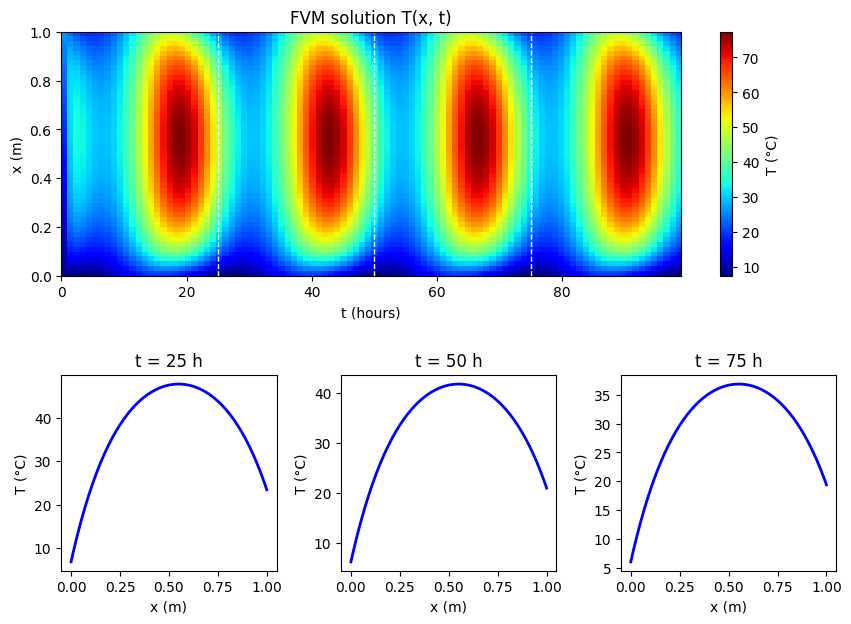

Saved fvm_reference_noise_free.npz and fvm_solution_noise_free.png


In [26]:
fig = plt.figure(figsize=(10, 7))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.8], hspace=0.45, wspace=0.3)

ax0 = fig.add_subplot(gs[0, :])
im = ax0.imshow(U.T, origin="lower", aspect="auto", cmap="jet",
                extent=[t.min(), t.max(), 0, PARAMS["H"]])
fig.colorbar(im, ax=ax0, label="T (°C)")
for tv in [25, 50, 75]:
    ax0.axvline(tv, color="w", ls="--", lw=1)
ax0.set_xlabel("t (hours)"); ax0.set_ylabel("x (m)")
ax0.set_title("FVM solution T(x, t)")

for i, tv in enumerate([25, 50, 75]):
    ax = fig.add_subplot(gs[1, i])
    # include the boundary values so the profile spans the full height
    xs = np.concatenate([[0.0], x, [PARAMS["H"]]])
    us = np.concatenate([[Ta[tv]], U[tv], [To[tv]]])
    ax.plot(xs, us, "b-", lw=2)
    ax.set_title(f"t = {tv} h"); ax.set_xlabel("x (m)"); ax.set_ylabel("T (°C)")

#plt.savefig("fvm_solution.png", dpi=150, bbox_inches="tight")
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()

np.savez(
    reference_file,
    x=x, t=t, U=U, Ta=Ta, To=To, K=K,
    N_cells=N_CELLS,
    substeps=SUBSTEPS,
    synthetic=not USE_REAL_DATA,
    experiment=experiment,
    **{f"param_{name}": value for name, value in PARAMS.items()}
)
print(f"Saved {reference_file} and {figure_file}")